We experiment here with a naive dataset and the FlowNet architecture.

# Generate OF data
First, we will generate a dataset of moving patterns on a image.

Then, we will use various datasets configurations in order to train a mini FlowNet inspired architecture. 

Bellow, you find some generic code for : 
* generate random patterns
* overlay a patch on a given image by generating a new one
* generate two frames corresponding to various motions

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import sklearn.model_selection as skms
import tensorflow as tf
from tensorflow.keras import layers, models

#pattern generation and overlay
def generate_pattern(w):
    return (np.random.rand(w,w,3)*255).astype(np.uint8)

def overlay_patch(img,patch,x,y):
    _img=img.copy()
    x0=max(0,x)
    y0=max(0,y)
    x1=min(x+patch.shape[0],img.shape[0])
    y1=min(y+patch.shape[1],img.shape[1])
    x2=x1-x
    y2=y1-y
    _img[x0:x1,y0:y1]=patch[(x0-x):x2,(y0-y):y2]
    return _img,(x0,y0,x1,y1)

#generate OF ground truth motion
def generate_motions(img,p,_min,_max,times):
    motions=[]
    for i in range(times):
        ok=False
        while not ok:
            x=int(np.random.randint(img.shape[0]-p.shape[0]/2))
            y=int(np.random.randint(img.shape[1]-p.shape[1]/2))
            xdx=int(np.random.randint(img.shape[0]-p.shape[0]/2))
            ydy=int(np.random.randint(img.shape[1]-p.shape[1]/2))
            ok=abs(xdx-x)<=_max and abs(xdx-x)>=_min and abs(ydy-y)<=_max and abs(ydy-y)>=_min
        
        _img1,(x0,y0,x1,y1)=overlay_patch(img,p,x,y)
        _img2,_=overlay_patch(img,p,xdx,ydy)
        
        _of=np.zeros((_img1.shape[0],_img1.shape[1],2))
        _of[x0:x1,y0:y1]=np.array([xdx-x,ydy-y])
        motions.append([cv2.cvtColor(_img1,cv2.COLOR_RGB2GRAY),cv2.cvtColor(_img2,cv2.COLOR_RGB2GRAY),_of])
    return motions

#visualisation
def layout_images(images, n_rows=None, n_cols=None, border_size=2):
    height, width, n_channels = images[0].shape
    height, width = height + border_size, width + border_size
    if n_cols is None or n_rows is None:
        n_cols = int(np.sqrt(len(images)))
        if n_cols**2 < len(images):
            n_cols += 1
        n_rows = n_cols
    output_img = np.ones((n_rows*height+border_size, n_cols*width+border_size, n_channels), dtype=images[0].dtype)*255
    for i, p in enumerate(images):
        r, c = i//n_cols, i%n_cols
        output_img[border_size+r*height:(r+1)*height, border_size+c*width:(c+1)*width] = p
    return output_img

def optical_flow_to_rgb(flow):
    # The representation relies on the HSV color space, where colors are represented by their hue (as an angle),
    # their saturation and their intensity (value)
    flow_hsv = np.zeros(flow.shape[:2] + (3,), dtype=np.float32)
    # The hue (H) is the orientation of optical flow vectors
    flow_hsv[...,0] = np.arctan2(flow[...,1], flow[...,0])/np.pi*180. + 180.
    # Saturation (S) is just a dummy dimension here
    flow_hsv[...,1] = 1.
    # Intensity (V) is used for the norm (amplitude) of flow vectors, normalized in [0,1]
    flow_hsv[...,2] = np.linalg.norm(flow, axis=2, ord=2) # norms (amplitudes) of vectors
    flow_hsv[...,2] = (flow_hsv[...,2] - np.min(flow_hsv[...,2])) / (np.max(flow_hsv[...,2]) - np.min(flow_hsv[...,2]))
    # The final image is converted back to RGB for display
    return cv2.cvtColor(flow_hsv, cv2.COLOR_HSV2RGB)

def show_motions_and_of(motions):
    ofs=[]
    for i in range(len(motions)):
        img1=motions[i][0]
        img2=motions[i][1]
        img_of=(optical_flow_to_rgb(motions[i][2])*255).astype(np.uint8)
        ofs.append(layout_images([cv2.cvtColor(img1,cv2.COLOR_GRAY2BGR),cv2.cvtColor(img2,cv2.COLOR_GRAY2BGR),img_of],1,3,2))
    plt.imshow(layout_images(ofs))
        

2025-12-11 15:01:18.229150: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-12-11 15:01:18.288801: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-12-11 15:01:19.731207: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Write a code to generate a dataset that contains 100 OF where 10 differents patterns of a size (10,10) generate 100 differents motions of low intensities ranging from 1 to 3 over a dark image of size (32,32).

Sample 10 motions for all the motions that where generated and use the function "show_motions_and_of" in order to visualize them.

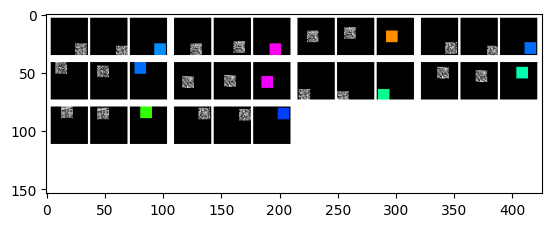

In [2]:
nb_patterns = 10
nb_motions = 10
img_size = 32
pattern_size = 10
motion_min = 1
motion_max = 3

all_motions = []
dark_img = np.zeros((img_size, img_size, 3), dtype=np.uint8)

for i in range(nb_patterns):
    p = generate_pattern(pattern_size)
    motions = generate_motions(dark_img, p, motion_min, motion_max, nb_motions)
    all_motions += motions

sample_indices = np.random.choice(len(all_motions), 10, replace=False)
sampled_motions = [all_motions[idx] for idx in sample_indices]
show_motions_and_of(sampled_motions)
plt.show()

# Network and training

Create a network that has the structure of an autoencoder with 1 convolutional layer followed by 1 (de)convolutional or convolutional transpose layers.

The input corresponds to a 2 channel matrix where the first channel corresponds to the first image and the second channel corresponds to the second image.

The ouput corresponds to the 2 channel matrix corresponding to the expected optical flow.

MSELoss can be used for tranining.

First, construct the X and y from the all_motions list and create a train/test configuration (using sklearn.model_selection.train_test_split)

In [3]:
X = np.zeros((len(all_motions), all_motions[0][0].shape[0], all_motions[0][0].shape[1], 2))
y = np.zeros((len(all_motions), all_motions[0][0].shape[0], all_motions[0][0].shape[1], 2))
for i in range(len(all_motions)):
    X[i, :, :, 0] = all_motions[i][0]
    X[i, :, :, 1] = all_motions[i][1]
    y[i] = all_motions[i][2]

x_train, x_test, y_train, y_test = skms.train_test_split(X, y)

In [4]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((75, 32, 32, 2), (25, 32, 32, 2), (75, 32, 32, 2), (25, 32, 32, 2))

Create the input tensor

In [5]:
inputs = tf.keras.Input(shape=x_train[0].shape)
print(len(x_train),inputs)

75 <KerasTensor shape=(None, 32, 32, 2), dtype=float32, sparse=False, ragged=False, name=keras_tensor>


Create the autoencoder architecture :

* encoder : 1 Conv2D layer with kernel size 3x3 + 1 maxpoling 2x2
* decoder : 1 Conv2DTranspose layer with kernel size 3x3 with stride 2 + 1 final Conv2D layer using 2 filters and a stride of one in order to reconstruct the 2 channels of the OF

For the encoder/decoder components you can start by using 64 filters and use "same" padding.

What activation function should you use for the last conv transpose layer ? ReLu would be a good fit ?

Use MSELoss

In [6]:
# Convolutional Layer
conv1 = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(inputs)
# Pooling Layer #1
pool1 = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), strides=2, padding='same')(conv1)

# Convolutional Transpose Layer
deconv1 = tf.keras.layers.Conv2DTranspose(64, (3, 3), strides=2, activation='relu', padding='same')(pool1)

# Final Convolutional Layer to reconstruct OF (2 channels)
OF = tf.keras.layers.Conv2D(2, (3, 3), activation=None, padding='same')(deconv1)

model = tf.keras.Model(inputs=inputs, outputs=OF)

mseloss = tf.keras.losses.MeanSquaredError()

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss=mseloss, metrics=['accuracy'])

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 2)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 32, 32, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 2)      │         1,154 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,298 (153.51 KB)

 Trainable params: 39,298 (153.51 KB)

 Non-trainable params: 0 (0.00 B)

You can use the following callback for visualizing at the end of each 5 epochs the evolution in terms of OF computation

In [7]:
train_samples=np.random.choice(range(y_train.shape[0]),6)
y_pred_train=model.predict(x_train[train_samples])
size=x_train[0].shape[0]

class CustomCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if epoch%5!=0:
            return
        res_imgs=[]
        y_pred_train=model.predict(x_train[train_samples])
        for i,s in enumerate(train_samples):
          _img1=x_train[s][:,:,0].reshape(size,size,1).astype(np.uint8)
          _img2=x_train[s][:,:,1].reshape(size,size,1).astype(np.uint8)
          img1=cv2.cvtColor(_img1,cv2.COLOR_GRAY2BGR)
          img2=cv2.cvtColor(_img2,cv2.COLOR_GRAY2BGR)
          of_ok=(optical_flow_to_rgb(y_train[s])*255).astype(np.uint8)
          of_pred=(optical_flow_to_rgb(y_pred_train[i])*255).astype(np.uint8)
          res_imgs.append(layout_images([img1,img2,of_ok,of_pred],1,4))
        plt.imshow(layout_images(res_imgs))
        plt.pause(0.1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step


Fit the model using 40 epochs and a batch size of 16

Epoch 1/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5184 - loss: 13.9686


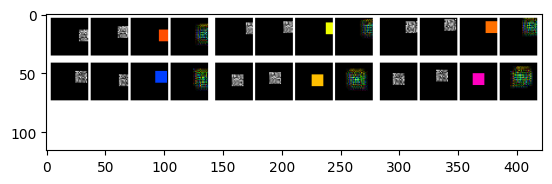

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step - accuracy: 0.3349 - loss: 11.9815
Epoch 2/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1442 - loss: 5.3455
Epoch 3/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1194 - loss: 4.0868
Epoch 4/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1132 - loss: 3.9105
Epoch 5/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1195 - loss: 3.4297
Epoch 6/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.1216 - loss: 3.003


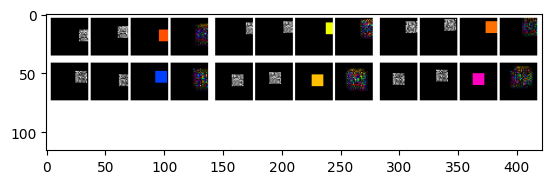

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.1262 - loss: 2.8014
Epoch 7/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1338 - loss: 2.4627
Epoch 8/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1405 - loss: 2.3393
Epoch 9/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1424 - loss: 2.1986
Epoch 10/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1400 - loss: 2.0396
Epoch 11/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1336 - loss: 1.921


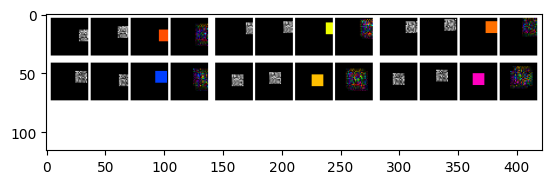

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.1343 - loss: 1.9282
Epoch 12/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.1317 - loss: 1.8494
Epoch 13/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1327 - loss: 1.7707
Epoch 14/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1356 - loss: 1.6940
Epoch 15/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1379 - loss: 1.6299
Epoch 16/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1363 - loss: 1.568


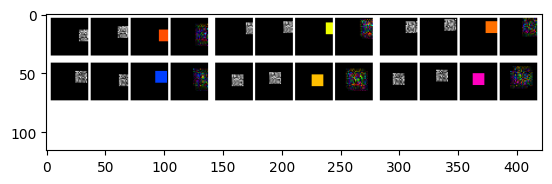

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.1388 - loss: 1.5735
Epoch 17/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1390 - loss: 1.5208
Epoch 18/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1388 - loss: 1.4733
Epoch 19/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1390 - loss: 1.4308
Epoch 20/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1396 - loss: 1.3927
Epoch 21/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.1379 - loss: 1.362


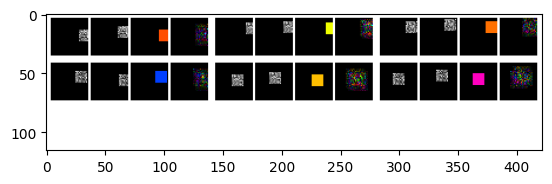

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.1398 - loss: 1.3581
Epoch 22/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1400 - loss: 1.3263
Epoch 23/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1406 - loss: 1.2970
Epoch 24/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1408 - loss: 1.2700
Epoch 25/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1410 - loss: 1.2448
Epoch 26/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1389 - loss: 1.224


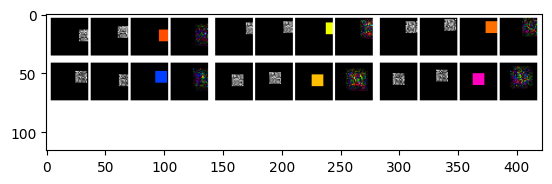

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.1415 - loss: 1.2210
Epoch 27/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1421 - loss: 1.1986
Epoch 28/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1423 - loss: 1.1775
Epoch 29/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1428 - loss: 1.1575
Epoch 30/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1431 - loss: 1.1385
Epoch 31/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.1418 - loss: 1.123


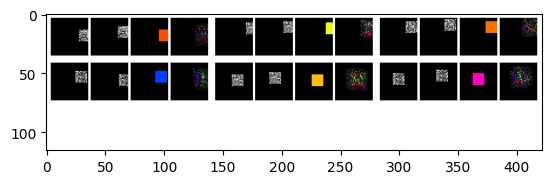

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.1432 - loss: 1.1204
Epoch 32/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.1433 - loss: 1.1031
Epoch 33/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1435 - loss: 1.0865
Epoch 34/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1434 - loss: 1.0706
Epoch 35/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1438 - loss: 1.0552
Epoch 36/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.1430 - loss: 1.042


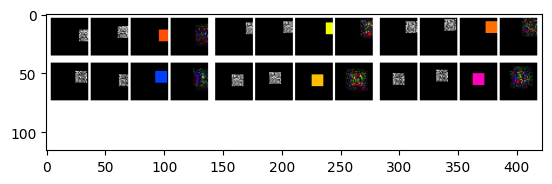

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.1442 - loss: 1.0404
Epoch 37/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1444 - loss: 1.0261
Epoch 38/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1448 - loss: 1.0122
Epoch 39/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1449 - loss: 0.9988
Epoch 40/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.1447 - loss: 0.9858


In [8]:
#random seed for tensorflow
tf.random.set_seed(42)
nb_epochs=40

x_train_arr=np.array(x_train).reshape(len(x_train),x_train[0].shape[0],x_train[0].shape[1],x_train[0].shape[2])
y_train_arr=np.array(y_train).reshape(len(y_train),y_train[0].shape[0],y_train[0].shape[1],y_train[0].shape[2])
model.fit(x=x_train_arr, y=y_train_arr, batch_size=16, epochs=nb_epochs,verbose=True,callbacks=[CustomCallback()])

Test 1/Compute the endpoint error metrics for the train (x_train) and test (x_test) data.

In [9]:
def endpoint_error(y_true, y_pred):
    # y_true, y_pred: (N, H, W, 2)
    return np.mean(np.linalg.norm(y_true - y_pred, axis=-1))

y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

epe_train = endpoint_error(y_train, y_pred_train)
epe_test = endpoint_error(y_test, y_pred_test)

print(f"Train endpoint error: {epe_train:.4f}")
print(f"Test endpoint error: {epe_test:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Train endpoint error: 0.5815
Test endpoint error: 0.5673


Test 2/ Generate some new test data (x_test2) by considering 10 new patterns. For a fair comparison generate as much test data as in x_test.shape[0]. It results that each new pattern will generate (x_test.shape[0]//10) motions.

In [10]:
# Let's generate new test data with 10 new patterns
nb_new_patterns = 10
nb_new_motions = x_test.shape[0] // nb_new_patterns
img_size = 32
pattern_size = 10
motion_min = 1
motion_max = 3

dark_img = np.zeros((img_size, img_size, 3), dtype=np.uint8)
all_motions_test2 = []

for i in range(nb_new_patterns):
    p = generate_pattern(pattern_size)
    motions = generate_motions(dark_img, p, motion_min, motion_max, nb_new_motions)
    all_motions_test2 += motions

# Prepare x_test2 and y_test2
x_test2 = np.zeros((len(all_motions_test2), img_size, img_size, 2))
y_test2 = np.zeros((len(all_motions_test2), img_size, img_size, 2))
for i in range(len(all_motions_test2)):
    x_test2[i, :, :, 0] = all_motions_test2[i][0]
    x_test2[i, :, :, 1] = all_motions_test2[i][1]
    y_test2[i] = all_motions_test2[i][2]

Increase the number of epochs, increase the number of training samples, number of filters, increase the autoencoder depth.

Report results.

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 2)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 256)    │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 2)      │         2,306 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,185,026 (4.52 MB)

 Trainable params: 1,185,026 (4.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/stepp - accuracy: 0.7615 - loss: 0.675


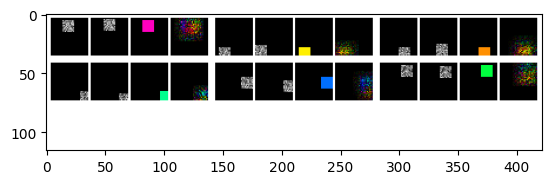

19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.7720 - loss: 0.5136
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.8083 - loss: 0.2893
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.7988 - loss: 0.1954
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.8069 - loss: 0.1455
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.8075 - loss: 0.1208
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/stepep - accuracy: 0.8127 - loss: 0.109


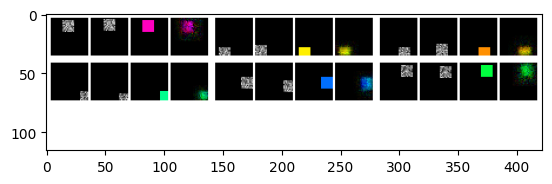

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.8061 - loss: 0.1054
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.8064 - loss: 0.0944
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.8065 - loss: 0.0861
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.8065 - loss: 0.0795
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8068 - loss: 0.0740
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/stepep - accuracy: 0.8139 - loss: 0.070


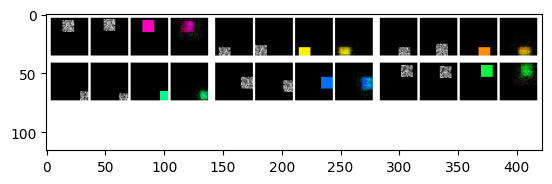

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.8072 - loss: 0.0695
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.8075 - loss: 0.0657
Epoch 13/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.8080 - loss: 0.0625
Epoch 14/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.8080 - loss: 0.0597
Epoch 15/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.8091 - loss: 0.0576
Epoch 16/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/stepep - accuracy: 0.8098 - loss: 0.056


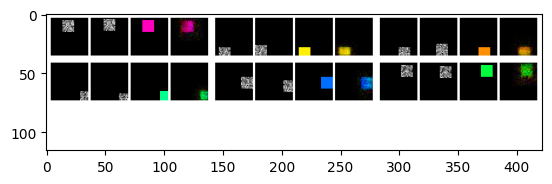

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.8102 - loss: 0.0558
Epoch 17/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8108 - loss: 0.0541
Epoch 18/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.8102 - loss: 0.0516
Epoch 19/100
19/19 ━━━━━━━━━━━━━━━━━━━━ -1s -48136us/step - accuracy: 0.8087 - loss: 0.0478
Epoch 20/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.8086 - loss: 0.0441
Epoch 21/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/stepep - accuracy: 0.8017 - loss: 0.042


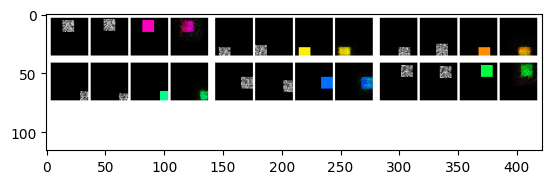

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - accuracy: 0.8090 - loss: 0.0414
Epoch 22/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.8091 - loss: 0.0393
Epoch 23/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.8094 - loss: 0.0376
Epoch 24/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.8099 - loss: 0.0360
Epoch 25/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.8100 - loss: 0.0345
Epoch 26/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/stepep - accuracy: 0.8055 - loss: 0.034


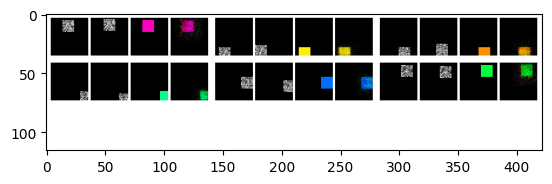

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.8106 - loss: 0.0331
Epoch 27/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.8109 - loss: 0.0318
Epoch 28/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.8112 - loss: 0.0305
Epoch 29/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.8113 - loss: 0.0294
Epoch 30/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.8110 - loss: 0.0283
Epoch 31/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/stepep - accuracy: 0.8062 - loss: 0.028


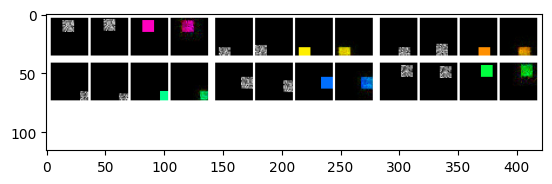

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.8109 - loss: 0.0272
Epoch 32/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.8111 - loss: 0.0262
Epoch 33/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.8112 - loss: 0.0253
Epoch 34/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.8112 - loss: 0.0244
Epoch 35/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8114 - loss: 0.0235
Epoch 36/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/stepep - accuracy: 0.8072 - loss: 0.023


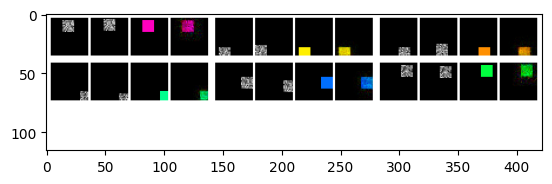

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.8117 - loss: 0.0227
Epoch 37/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.8116 - loss: 0.0219
Epoch 38/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.8113 - loss: 0.0212
Epoch 39/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.8115 - loss: 0.0205
Epoch 40/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.8116 - loss: 0.0199
Epoch 41/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/stepep - accuracy: 0.8072 - loss: 0.019


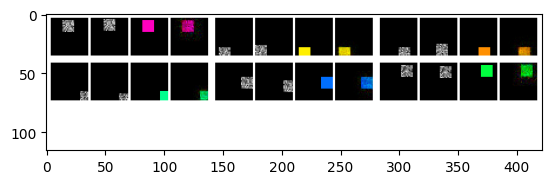

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.8117 - loss: 0.0192
Epoch 42/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8115 - loss: 0.0186
Epoch 43/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.8115 - loss: 0.0181
Epoch 44/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8104 - loss: 0.0175
Epoch 45/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.8069 - loss: 0.0170
Epoch 46/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/stepep - accuracy: 0.7940 - loss: 0.017


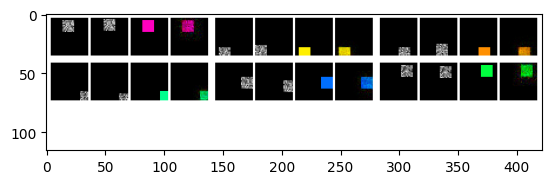

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.7891 - loss: 0.0165
Epoch 47/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.7621 - loss: 0.0160
Epoch 48/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.7414 - loss: 0.0155
Epoch 49/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.7172 - loss: 0.0151
Epoch 50/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.6995 - loss: 0.0147
Epoch 51/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/stepep - accuracy: 0.6836 - loss: 0.014


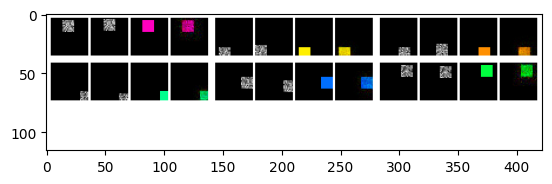

19/19 ━━━━━━━━━━━━━━━━━━━━ -0s -24079us/step - accuracy: 0.6858 - loss: 0.0143
Epoch 52/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.6697 - loss: 0.0140
Epoch 53/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.6532 - loss: 0.0136
Epoch 54/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.6358 - loss: 0.0133
Epoch 55/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.6119 - loss: 0.0130
Epoch 56/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/stepep - accuracy: 0.5924 - loss: 0.013


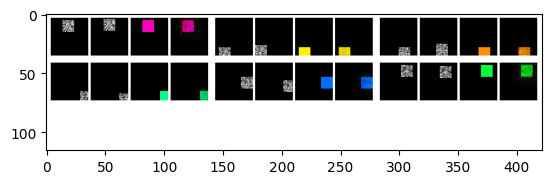

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.5917 - loss: 0.0127
Epoch 57/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.5678 - loss: 0.0124
Epoch 58/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.5529 - loss: 0.0122
Epoch 59/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.5391 - loss: 0.0119
Epoch 60/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.5269 - loss: 0.0118
Epoch 61/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/stepep - accuracy: 0.5069 - loss: 0.012


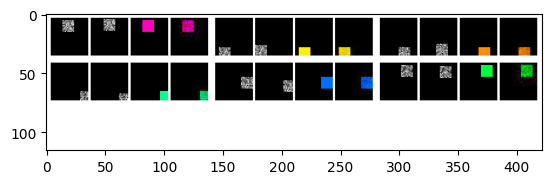

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.5133 - loss: 0.0117
Epoch 62/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.5045 - loss: 0.0116
Epoch 63/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.4960 - loss: 0.0117
Epoch 64/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.4918 - loss: 0.0120
Epoch 65/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.4862 - loss: 0.0128
Epoch 66/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/stepep - accuracy: 0.4589 - loss: 0.014


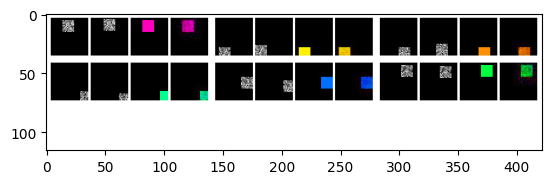

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.4816 - loss: 0.0156
Epoch 67/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.4737 - loss: 0.0243
Epoch 68/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.4595 - loss: 0.0208
Epoch 69/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.4889 - loss: 0.0198
Epoch 70/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.5082 - loss: 0.0230
Epoch 71/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/stepep - accuracy: 0.5541 - loss: 0.031


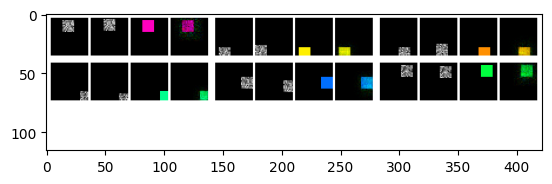

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.5319 - loss: 0.0299
Epoch 72/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.5688 - loss: 0.0263
Epoch 73/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.5638 - loss: 0.0185
Epoch 74/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - accuracy: 0.5904 - loss: 0.0194
Epoch 75/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.6209 - loss: 0.0225
Epoch 76/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/stepep - accuracy: 0.6008 - loss: 0.024


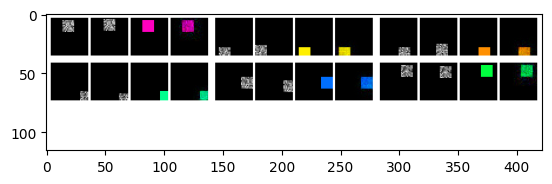

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.6247 - loss: 0.0225
Epoch 77/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.6441 - loss: 0.0136
Epoch 78/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.6449 - loss: 0.0103
Epoch 79/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.6233 - loss: 0.0100
Epoch 80/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.6037 - loss: 0.0100
Epoch 81/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/stepep - accuracy: 0.5948 - loss: 0.010


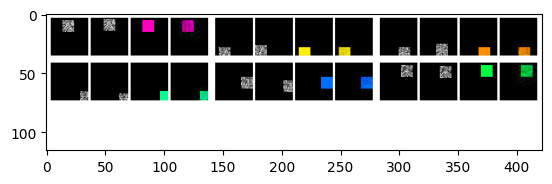

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.5871 - loss: 0.0097
Epoch 82/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.5675 - loss: 0.0092
Epoch 83/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step - accuracy: 0.5575 - loss: 0.0086
Epoch 84/100
19/19 ━━━━━━━━━━━━━━━━━━━━ -1s -31417us/step - accuracy: 0.5501 - loss: 0.0082
Epoch 85/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.5450 - loss: 0.0078
Epoch 86/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/stepep - accuracy: 0.5454 - loss: 0.007


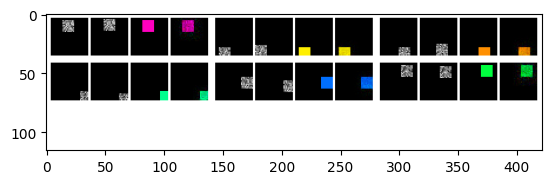

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.5405 - loss: 0.0075
Epoch 87/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.5361 - loss: 0.0073
Epoch 88/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.5330 - loss: 0.0071
Epoch 89/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.5298 - loss: 0.0069
Epoch 90/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.5278 - loss: 0.0067
Epoch 91/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/stepep - accuracy: 0.5317 - loss: 0.006


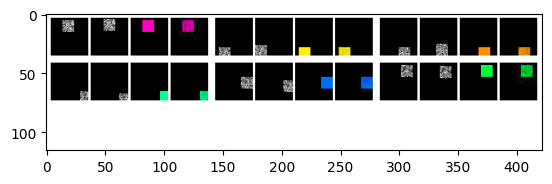

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.5239 - loss: 0.0065
Epoch 92/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.5229 - loss: 0.0063
Epoch 93/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.5207 - loss: 0.0062
Epoch 94/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.5194 - loss: 0.0060
Epoch 95/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.5160 - loss: 0.0059
Epoch 96/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/stepep - accuracy: 0.5198 - loss: 0.005


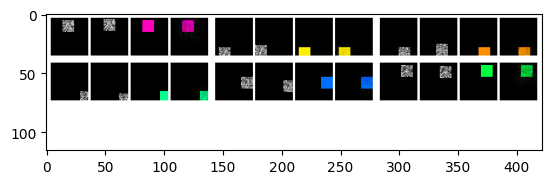

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.5144 - loss: 0.0057
Epoch 97/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.5109 - loss: 0.0056
Epoch 98/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.5091 - loss: 0.0055
Epoch 99/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.5082 - loss: 0.0054
Epoch 100/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.5081 - loss: 0.0053


In [11]:
# Let' increase number of epochs
nb_epochs = 100

# Also let's increase number of training samples
nb_patterns = 20  # doubled
nb_motions = 20   # doubled
img_size = 32
pattern_size = 10
motion_min = 1
motion_max = 3

all_motions = []
dark_img = np.zeros((img_size, img_size, 3), dtype=np.uint8)
for i in range(nb_patterns):
    p = generate_pattern(pattern_size)
    motions = generate_motions(dark_img, p, motion_min, motion_max, nb_motions)
    all_motions += motions

X = np.zeros((len(all_motions), img_size, img_size, 2))
y = np.zeros((len(all_motions), img_size, img_size, 2))
for i in range(len(all_motions)):
    X[i, :, :, 0] = all_motions[i][0]
    X[i, :, :, 1] = all_motions[i][1]
    y[i] = all_motions[i][2]

x_train, x_test, y_train, y_test = skms.train_test_split(X, y)

# Let's increase number of filters and depth in autoencoder
inputs = tf.keras.Input(shape=x_train[0].shape)
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(inputs)
x = layers.MaxPooling2D(pool_size=(2, 2), strides=2, padding='same')(x)
x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D(pool_size=(2, 2), strides=2, padding='same')(x)
x = layers.Conv2DTranspose(256, (3, 3), strides=2, activation='relu', padding='same')(x)
x = layers.Conv2DTranspose(128, (3, 3), strides=2, activation='relu', padding='same')(x)
outputs = layers.Conv2D(2, (3, 3), activation=None, padding='same')(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss=tf.keras.losses.MeanSquaredError(), metrics=['accuracy'])
model.summary()

model.fit(x=x_train, y=y_train, batch_size=16, epochs=nb_epochs, verbose=True, callbacks=[CustomCallback()])

In [12]:
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)
epe_train = endpoint_error(y_train, y_pred_train)
epe_test = endpoint_error(y_test, y_pred_test)

print(f"Train endpoint error: {epe_train:.4f}")
print(f"Test endpoint error: {epe_test:.4f}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
Train endpoint error: 0.0513
Test endpoint error: 0.0860


What can you conclude ?

Answer:

# Back to the data ... and the network

Let's try to make the data more challenging by increasing the complexity.

Let's consider the following configurations: 

a) Generate patterns of fixed size (10) while increasing the motion amplitude (5 to 15)

b) Generate patterns of various sizes (3-9-15) while maintaining small motions (1 to 3).

c) Generate patterns of various sizes (3-9-15) while covering small to large motion amplitudes (1 to 15)

What are the train and test performances with regard to the endpoint error metric ?

What updates can be made to the architecture in order to cope with the new configurations ?

If you are bringing updates to the architecture, please provide the updated results.


In [ ]:
# Configuration a: Fixed pattern size, increased motion amplitude (5 to 15)
nb_patterns = 10
nb_motions = 10
img_size = 32
pattern_size = 10
motion_min = 5
motion_max = 15 # increased

all_motions_a = []
dark_img = np.zeros((img_size, img_size, 3), dtype=np.uint8)

for i in range(nb_patterns):
    p = generate_pattern(pattern_size)
    motions = generate_motions(dark_img, p, motion_min, motion_max, nb_motions)
    all_motions_a += motions

# Prepare X and y for this configuration
X_a = np.zeros((len(all_motions_a), img_size, img_size, 2))
y_a = np.zeros((len(all_motions_a), img_size, img_size, 2))
for i in range(len(all_motions_a)):
    X_a[i, :, :, 0] = all_motions_a[i][0]
    X_a[i, :, :, 1] = all_motions_a[i][1]
    y_a[i] = all_motions_a[i][2]

x_train_a, x_test_a, y_train_a, y_test_a = skms.train_test_split(X_a, y_a)

In [13]:
# Evaluate endpoint error for configuration a (already generated in cell 25)
y_pred_train_a = model.predict(x_train_a)
y_pred_test_a = model.predict(x_test_a)
epe_train_a = endpoint_error(y_train_a, y_pred_train_a)
epe_test_a = endpoint_error(y_test_a, y_pred_test_a)
print(f"Config a - Train endpoint error: {epe_train_a:.4f}")
print(f"Config a - Test endpoint error: {epe_test_a:.4f}")

NameError: name 'x_train_a' is not defined

In [ ]:
# Configuration b: Various pattern sizes, small motions (1 to 3)
pattern_sizes_b = [3, 9, 15]
nb_patterns_b = 10
nb_motions_b = 10
motion_min_b = 1
motion_max_b = 3
all_motions_b = []
for size in pattern_sizes_b:
    for i in range(nb_patterns_b):
        p = generate_pattern(size)
        motions = generate_motions(dark_img, p, motion_min_b, motion_max_b, nb_motions_b)
        all_motions_b += motions
X_b = np.zeros((len(all_motions_b), img_size, img_size, 2))
y_b = np.zeros((len(all_motions_b), img_size, img_size, 2))
for i in range(len(all_motions_b)):
    X_b[i, :, :, 0] = all_motions_b[i][0]
    X_b[i, :, :, 1] = all_motions_b[i][1]
    y_b[i] = all_motions_b[i][2]
x_train_b, x_test_b, y_train_b, y_test_b = skms.train_test_split(X_b, y_b)
y_pred_train_b = model.predict(x_train_b)
y_pred_test_b = model.predict(x_test_b)
epe_train_b = endpoint_error(y_train_b, y_pred_train_b)
epe_test_b = endpoint_error(y_test_b, y_pred_test_b)
print(f"Config b - Train endpoint error: {epe_train_b:.4f}")
print(f"Config b - Test endpoint error: {epe_test_b:.4f}")


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Config b - Train endpoint error: 0.1596
Config b - Test endpoint error: 0.1621


In [ ]:
# Configuration c: Various pattern sizes, motion amplitudes (1 to 15)
pattern_sizes_c = [3, 9, 15]
nb_patterns_c = 10
nb_motions_c = 10
motion_min_c = 1
motion_max_c = 15
all_motions_c = []
for size in pattern_sizes_c:
    for i in range(nb_patterns_c):
        p = generate_pattern(size)
        motions = generate_motions(dark_img, p, motion_min_c, motion_max_c, nb_motions_c)
        all_motions_c += motions
X_c = np.zeros((len(all_motions_c), img_size, img_size, 2))
y_c = np.zeros((len(all_motions_c), img_size, img_size, 2))
for i in range(len(all_motions_c)):
    X_c[i, :, :, 0] = all_motions_c[i][0]
    X_c[i, :, :, 1] = all_motions_c[i][1]
    y_c[i] = all_motions_c[i][2]
x_train_c, x_test_c, y_train_c, y_test_c = skms.train_test_split(X_c, y_c)
y_pred_train_c = model.predict(x_train_c)
y_pred_test_c = model.predict(x_test_c)
epe_train_c = endpoint_error(y_train_c, y_pred_train_c)
epe_test_c = endpoint_error(y_test_c, y_pred_test_c)
print(f"Config c - Train endpoint error: {epe_train_c:.4f}")
print(f"Config c - Test endpoint error: {epe_test_c:.4f}")


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Config c - Train endpoint error: 0.8831
Config c - Test endpoint error: 1.0715


In [23]:
# Architectural update suggestion for more challenging data, we can:
# - Increase depth and number of filters
# - Add more Conv2D/Conv2DTranspose layers
# - Use BatchNormalization and Dropout for regularization

inputs = tf.keras.Input(shape=x_train_c[0].shape)
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(inputs)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(pool_size=(2, 2), strides=2, padding='same')(x)
x = layers.Conv2D(256, (3, 3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(pool_size=(2, 2), strides=2, padding='same')(x)
x = layers.Conv2D(512, (3, 3), activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2DTranspose(256, (3, 3), strides=2, activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2DTranspose(128, (3, 3), strides=2, activation='relu', padding='same')(x)
x = layers.BatchNormalization()(x)
outputs = layers.Conv2D(2, (3, 3), activation=None, padding='same')(x)
model_updated = tf.keras.Model(inputs=inputs, outputs=outputs)
model_updated.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                      loss=tf.keras.losses.MeanSquaredError(), metrics=['accuracy'])
model_updated.summary()
model_updated.fit(x=x_train_c, y=y_train_c, batch_size=16, epochs=100, verbose=True, callbacks=[CustomCallback()])

y_pred_train_c_upd = model_updated.predict(x_train_c)
y_pred_test_c_upd = model_updated.predict(x_test_c)
epe_train_c_upd = endpoint_error(y_train_c, y_pred_train_c_upd)
epe_test_c_upd = endpoint_error(y_test_c, y_pred_test_c_upd)
print(f"Config c (updated) - Train endpoint error: {epe_train_c_upd:.4f}")
print(f"Config c (updated) - Test endpoint error: {epe_test_c_upd:.4f}")

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 32, 32, 2)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 128)    │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 16, 16, 256)    │     1,179,904 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 32, 32, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 32, 32, 2)      │         2,306 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,960,130 (11.29 MB)

 Trainable params: 2,957,570 (11.28 MB)

 Non-trainable params: 2,560 (10.00 KB)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/steptep - accuracy: 0.4834 - loss: 7.076


ValueError: cannot reshape array of size 1024 into shape (15,15,1)